In [1]:
import numpy as np
import pandas as pd

import pickle

import copy
import math
import scipy

import os 

import matplotlib.pyplot as plt
import scipy.stats


#----------------------------------------

import poseigen_seaside.basics as se
import poseigen_seaside.visuals as viz
import poseigen_trident.preass as pa

import poseigen_binmeths.bin_utils as bu

In [2]:
os.getcwd()

figs_folder = se.NewFolder('figs')

(array([  645.,  2893.,  7896., 15981., 22786., 22575., 15872.,  7929.,
         2751.,   672.]),
 array([0. , 0.9, 1.8, 2.7, 3.6, 4.5, 5.4, 6.3, 7.2, 8.1, 9. ]),
 <BarContainer object of 10 artists>)

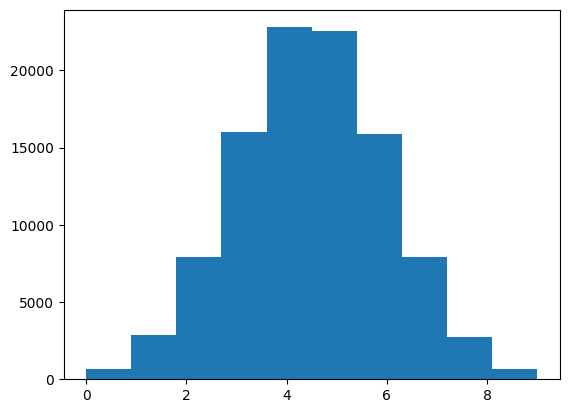

In [3]:
plusminus = 3
my_std = 1

cent = 0

myclip_a = cent-plusminus
myclip_b = cent+plusminus
my_mean = (myclip_a + myclip_b) / 2
a, b = (myclip_a - my_mean) / my_std, (myclip_b - my_mean) / my_std



sizo = 100000

go = scipy.stats.truncnorm.rvs(a, b, loc = my_mean, scale = my_std, size = sizo)

binx = 10

go_uni = bu.HistUni(go, bins = binx)
go_bind = bu.Binner(go, uni = go_uni)

plt.hist(go_bind)

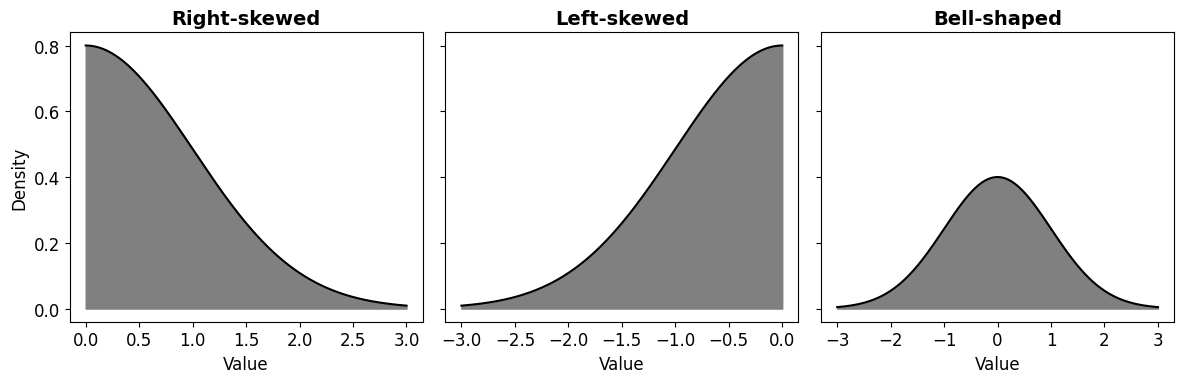

In [4]:
plusminus = 3
my_std = 1
cent = 0
myclip_a = cent - plusminus
myclip_b = cent + plusminus
my_mean = (myclip_a + myclip_b) / 2

az = [0, -3, -3]
bz = [3, 0, 3]

plt.rcParams.update({'font.size': 12})
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)

titles = ['Right-skewed', 'Left-skewed', 'Bell-shaped']

for ax, a1, b1, title in zip(axes, az, bz, titles):
    x_min = my_mean + a1 * my_std
    x_max = my_mean + b1 * my_std
    x = np.linspace(x_min, x_max, 500)
    pdf = scipy.stats.truncnorm.pdf(x, a1, b1, loc=my_mean, scale=my_std)
    ax.plot(x, pdf, color='black', linewidth=1.5)
    ax.fill_between(x, pdf, color='gray')
    ax.set_xlabel('Value')
    ax.set_title(title, fontsize=14, fontweight='bold')

axes[0].set_ylabel('Density')

plt.tight_layout()
plt.savefig(figs_folder + 'unimodal_data.svg', format='svg', bbox_inches='tight')
plt.show()

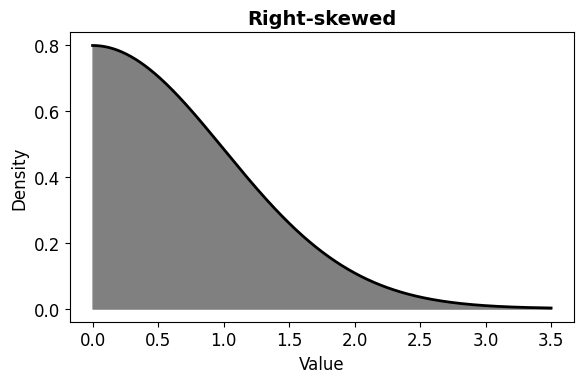

In [5]:
plusminus = 3
my_std = 1
cent = 0
myclip_a = cent - plusminus
myclip_b = cent + plusminus
my_mean = (myclip_a + myclip_b) / 2
a, b = (myclip_a - my_mean) / my_std, (myclip_b - my_mean) / my_std

a1, b1 = 0, 3.5

x_min = my_mean + a1 * my_std
x_max = my_mean + b1 * my_std
x = np.linspace(x_min, x_max, 500)
pdf = scipy.stats.truncnorm.pdf(x, a1, b1, loc=my_mean, scale=my_std)

plt.rcParams.update({'font.size': 12})
plt.figure(figsize=(6, 4))
plt.plot(x, pdf, color='black', linewidth=2)
plt.fill_between(x, pdf, color='grey')
plt.xlabel('Value')
plt.ylabel('Density')
plt.title('Right-skewed', fontsize = 14, fontweight = 'bold')

plt.tight_layout()
plt.savefig(figs_folder + 'right_skewed.svg', format='svg', bbox_inches='tight')
plt.show()

sizo = 10000
right_skewed_data = scipy.stats.truncnorm.rvs(a1, b1, loc=my_mean, scale=my_std, size=sizo)

In [6]:
import numpy as np

rng = np.random.default_rng(42)
x = right_skewed_data

# Indices allowed in test (<= 1.0) and indices forced to train (> 1.0)
eligible_test_idx = np.where(x <= 1.0)[0]
forced_train_idx = np.where(x > 1.0)[0]

# Choose desired test size as a fraction of all data
test_frac = 0.20
n_test_target = int(round(test_frac * len(x)))
n_test = min(n_test_target, len(eligible_test_idx))  # cannot exceed eligible pool

# Sample test from eligible values only (no replacement)
test_idx = rng.choice(eligible_test_idx, size=n_test, replace=False)

# Remaining eligible values + all >1.0 values go to train
remaining_eligible_idx = np.setdiff1d(eligible_test_idx, test_idx, assume_unique=False)
train_idx = np.concatenate([remaining_eligible_idx, forced_train_idx])

# Optional shuffle for randomness in order
rng.shuffle(train_idx)
rng.shuffle(test_idx)

training_set = x[train_idx]
testing_set = x[test_idx]

# Guarantees
assert np.all(testing_set <= 1.0)
assert len(training_set) + len(testing_set) == len(x)

print("Total:", len(x))
print("Train:", len(training_set), "max=", training_set.max())
print("Test :", len(testing_set), "max=", testing_set.max())

Total: 10000
Train: 8000 max= 3.3804496165837126
Test : 2000 max= 0.9994372442082875


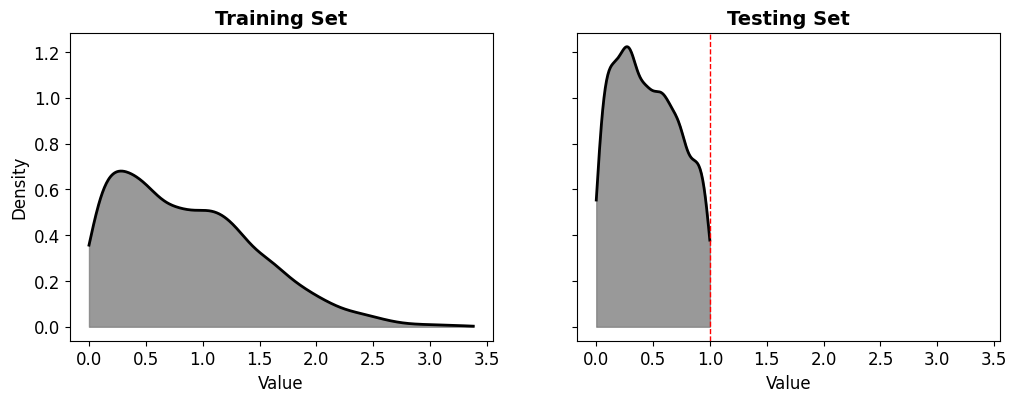

In [7]:
import scipy.stats as st


x_common = np.linspace(training_set.min(), training_set.max(), 600)

kde_train = st.gaussian_kde(training_set, bw_method=0.2)
kde_test = st.gaussian_kde(testing_set, bw_method=0.2)

y_train = kde_train(x_common)
y_test = kde_test(x_common)

y_test_masked = y_test.copy()
y_test_masked[x_common > 1.0] = np.nan

plt.rcParams.update({"font.size": 12})
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, sharex=True)

axes[0].plot(x_common, y_train, color="black", linewidth=2)
axes[0].fill_between(x_common, y_train, color="gray", alpha=0.8)
axes[0].set_title("Training Set", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Value")
axes[0].set_ylabel("Density")

axes[1].plot(x_common, y_test_masked, color="black", linewidth=2)
axes[1].fill_between(x_common, y_test_masked, color="gray", alpha=0.8)
axes[1].axvline(1.0, color="red", linestyle="--", linewidth=1)
axes[1].set_title("Testing Set", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Value")

plt.savefig(figs_folder + 'bad_split.svg', format='svg', bbox_inches='tight')


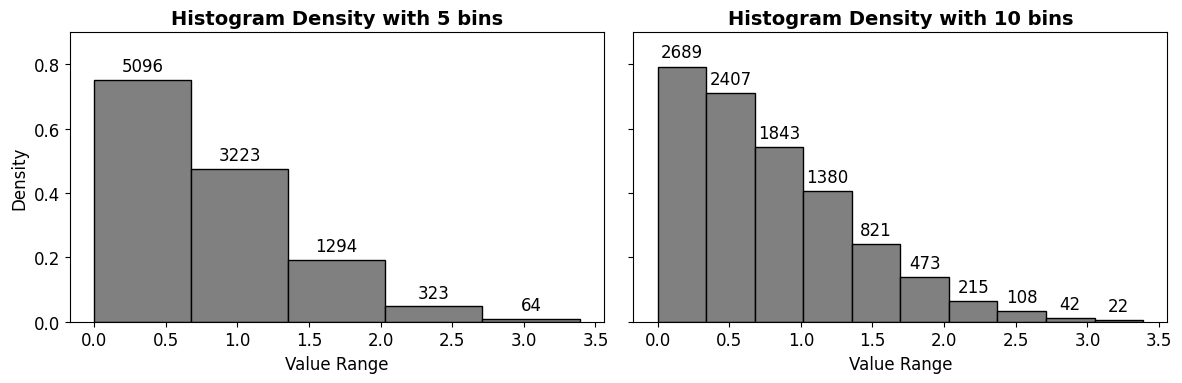

In [10]:
right_skewed_data = scipy.stats.truncnorm.rvs(a1, b1, loc=my_mean, scale=my_std, size=sizo)

# plt.rcParams.update({'font.size': 12})
# fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

# for ax, num_bins in zip(axes, [5, 10]):
#     bin_edges = np.linspace(right_skewed_data.min(), right_skewed_data.max(), num_bins + 1)
#     bin_counts, _ = np.histogram(right_skewed_data, bins=bin_edges)
#     bin_widths = np.diff(bin_edges)

#     ax.bar(bin_edges[:-1], bin_counts, width=bin_widths, align='edge', edgecolor='black', color='grey')

#     for edge, count, width in zip(bin_edges[:-1], bin_counts, bin_widths):
#         ax.text(edge + width / 2, count, str(count), ha='center', va='bottom', fontsize=12)

#     ax.set_xlabel('Value Range')
#     ax.set_title(f'Histogram with {num_bins} bins', fontsize=14, fontweight='bold')

# axes[0].set_ylabel('Frequency')
# plt.tight_layout()
# plt.savefig(figs_folder + 'bin_histogram.svg', format='svg', bbox_inches='tight')
# plt.show()

right_skewed_data = scipy.stats.truncnorm.rvs(a1, b1, loc=my_mean, scale=my_std, size=sizo)

plt.rcParams.update({'font.size': 12})
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, num_bins in zip(axes, [5, 10]):
    bin_edges = np.linspace(right_skewed_data.min(), right_skewed_data.max(), num_bins + 1)
    bin_counts, _ = np.histogram(right_skewed_data, bins=bin_edges)
    bin_widths = np.diff(bin_edges)

    # Density = proportion per bin divided by bin width
    bin_density = bin_counts / (bin_counts.sum() * bin_widths)

    ax.bar(
        bin_edges[:-1], bin_density, width=bin_widths, align='edge',
        edgecolor='black', color='grey'
    )

    # Annotate each bar with number of members in that bin
    y_offset = max(bin_density.max() * 0.02, 1e-6)
    for edge, count, width, dens in zip(bin_edges[:-1], bin_counts, bin_widths, bin_density):
        ax.text(
            edge + width / 2, dens + y_offset, str(count),
            ha='center', va='bottom', fontsize=12
        )

    ax.set_xlabel('Value Range')
    ax.set_title(f'Histogram Density with {num_bins} bins', fontsize=14, fontweight='bold')

axes[0].set_ylabel('Density')
axes[0].set_ylim(0, 0.9)
plt.tight_layout()
plt.savefig(figs_folder + 'bin_histogram_density_annotated.svg', format='svg', bbox_inches='tight')
plt.show()

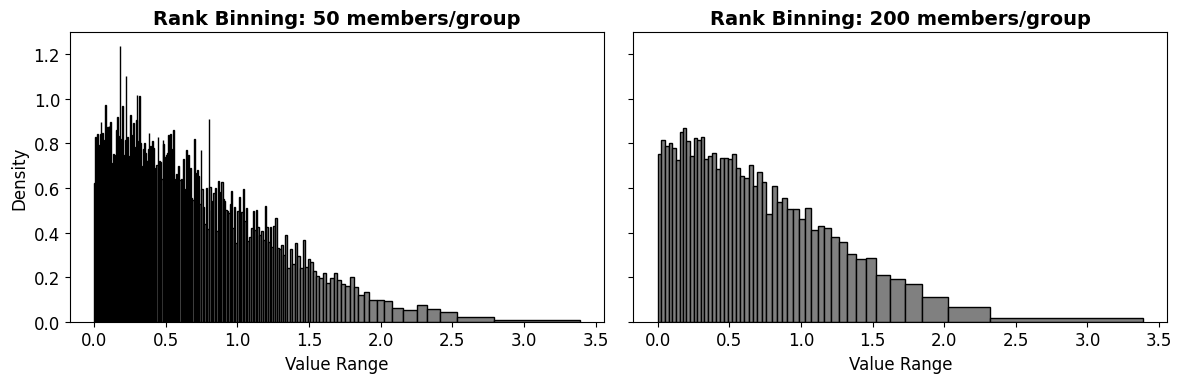

In [11]:
# plt.rcParams.update({'font.size': 12})
# fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

# for ax, members_per_group in zip(axes, [50, 200]):
#     sorted_data = np.sort(right_skewed_data)
#     n = len(sorted_data)

#     indices = np.arange(0, n, members_per_group)
#     bin_edges = sorted_data[indices]
#     bin_edges = np.append(bin_edges, sorted_data[-1])

#     bin_counts, _ = np.histogram(right_skewed_data, bins=bin_edges)
#     bin_widths = np.diff(bin_edges)

#     ax.bar(bin_edges[:-1], bin_counts, width=bin_widths, align='edge',
#            edgecolor='black', color='grey')
#     ax.set_xlabel('Value Range')
#     ax.set_title(f'Rank Binning: {members_per_group} members/group', fontsize=14, fontweight='bold')

# axes[0].set_ylabel('Frequency')
# plt.tight_layout()
# plt.savefig(figs_folder + 'bin_rank.svg', format='svg', bbox_inches='tight')
# plt.show()

plt.rcParams.update({'font.size': 12})
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, members_per_group in zip(axes, [50, 200]):
    sorted_data = np.sort(right_skewed_data)
    n = len(sorted_data)

    indices = np.arange(0, n, members_per_group)
    bin_edges = sorted_data[indices]
    bin_edges = np.append(bin_edges, sorted_data[-1])

    bin_counts, _ = np.histogram(right_skewed_data, bins=bin_edges)
    bin_widths = np.diff(bin_edges)

    # Density = count / (N * bin width)
    bin_density = bin_counts / (bin_counts.sum() * bin_widths)

    ax.bar(
        bin_edges[:-1], bin_density, width=bin_widths, align='edge',
        edgecolor='black', color='grey'
    )
    ax.set_xlabel('Value Range')
    ax.set_title(f'Rank Binning: {members_per_group} members/group', fontsize=14, fontweight='bold')

axes[0].set_ylabel('Density')
plt.tight_layout()
plt.savefig(figs_folder + 'bin_rank_density.svg', format='svg', bbox_inches='tight')
plt.show()

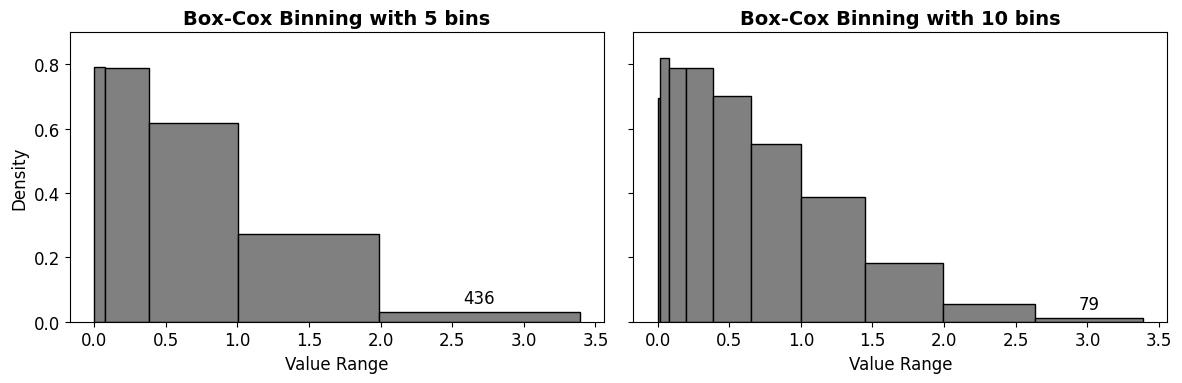

In [14]:
from scipy.stats import boxcox

shift = max(0, -right_skewed_data.min()) + 1e-6
data_pos = right_skewed_data + shift
transformed, lam = boxcox(data_pos)

# plt.rcParams.update({'font.size': 12})
# fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

# for ax, num_bins in zip(axes, [5, 10]):
#     bin_counts, bin_edges_t = np.histogram(transformed, bins=num_bins)

#     if lam == 0:
#         bin_edges_orig = np.exp(bin_edges_t) - shift
#     else:
#         bin_edges_orig = (bin_edges_t * lam + 1) ** (1 / lam) - shift

#     bin_widths_orig = np.diff(bin_edges_orig)

#     ax.bar(bin_edges_orig[:-1], bin_counts, width=bin_widths_orig, align='edge',
#            edgecolor='black', color='grey')

#     for edge, count, width in zip(bin_edges_orig[:-1], bin_counts, bin_widths_orig):
#         ax.text(edge + width / 2, count, str(count), ha='center', va='bottom', fontsize=12)

#     ax.set_xlabel('Value Range')
#     ax.set_title(f'Box-Cox Binning with {num_bins} bins', fontsize=14, fontweight='bold')

# axes[0].set_ylabel('Frequency')
# plt.tight_layout()
# plt.savefig(figs_folder + 'bin_boxcox.svg', format='svg', bbox_inches='tight')
# plt.show()

plt.rcParams.update({'font.size': 12})
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, num_bins in zip(axes, [5, 10]):
    bin_counts, bin_edges_t = np.histogram(transformed, bins=num_bins)

    if lam == 0:
        bin_edges_orig = np.exp(bin_edges_t) - shift
    else:
        bin_edges_orig = (bin_edges_t * lam + 1) ** (1 / lam) - shift

    bin_widths_orig = np.diff(bin_edges_orig)

    # Density = count / (N * bin width)
    bin_density = bin_counts / (bin_counts.sum() * bin_widths_orig)

    ax.bar(
        bin_edges_orig[:-1], bin_density, width=bin_widths_orig, align='edge',
        edgecolor='black', color='grey'
    )

    # Annotate bars with member counts
    y_offset = max(bin_density.max() * 0.02, 1e-6)
    # for edge, count, width, dens in zip(bin_edges_orig[:-1], bin_counts, bin_widths_orig, bin_density):
    #     ax.text(
    #         edge + width / 2, dens + y_offset, str(count),
    #         ha='center', va='bottom', fontsize=12
    #     )
    if len(bin_counts) > 0:
        edge = bin_edges_orig[:-1][-1]
        width = bin_widths_orig[-1]
        dens = bin_density[-1]
        count = bin_counts[-1]
        ax.text(
            edge + width / 2, dens + y_offset, str(count),
            ha='center', va='bottom', fontsize=12
        )

    ax.set_xlabel('Value Range')
    ax.set_title(f'Box-Cox Binning with {num_bins} bins', fontsize=14, fontweight='bold')

axes[0].set_ylabel('Density')
axes[0].set_ylim(0, 0.9)  # optional, keeps labels from clipping
plt.tight_layout()
plt.savefig(figs_folder + 'bin_boxcox_density_annotated.svg', format='svg', bbox_inches='tight')
plt.show()

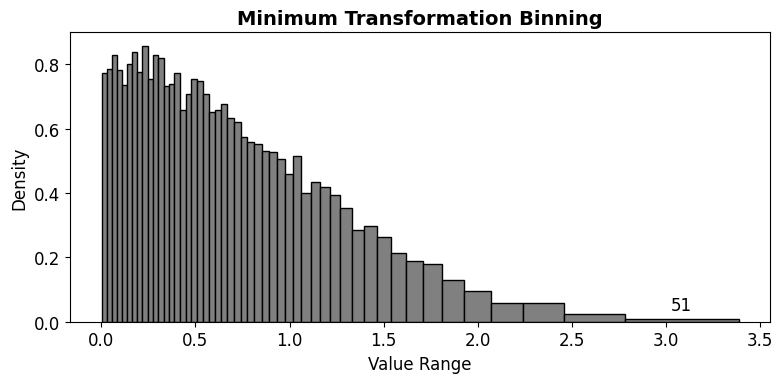

In [29]:
trans_mode = [se.tanh, {}]
revtrans_mode = [se.revtanh, {}]

binopt_args = {'mode': trans_mode, 'geometric': False,
                'obs_min': 48, 'bins_min': 10, 'bins_max': 50, 'bins_increm': 2, 
                'scalefax_min': 0.05, 'scalefax_increm': 0.01, 'scalefax_max': 3}

binopt_out = bu.BinOpt(right_skewed_data, **binopt_args)
num_bins, scalefax = binopt_out

bin_ranges = bu.ObjUni(right_skewed_data, scalefactor=scalefax,
                        mode=trans_mode, mode_rev=revtrans_mode, 
                        bins=num_bins)

bin_edges_from_ranges = np.append(bin_ranges[:, 0], bin_ranges[-1, 1])
bin_counts, _ = np.histogram(right_skewed_data, bins=bin_edges_from_ranges)
bin_widths = np.diff(bin_edges_from_ranges)

# plt.rcParams.update({'font.size': 12})
# plt.figure(figsize=(12, 4))
# plt.bar(bin_edges_from_ranges[:-1], bin_counts, width=bin_widths, align='edge',
#         edgecolor='black', color='grey')

# plt.xlabel('Value Range')
# plt.ylabel('Frequency')
# plt.title('Minimum Transformation Binning', fontsize=14, fontweight='bold')
# plt.tight_layout()
# plt.savefig(figs_folder + 'bin_mtb.svg', format='svg', bbox_inches='tight')
# plt.show()

# Density = count / (N * bin width)
bin_density = bin_counts / (bin_counts.sum() * bin_widths)

plt.rcParams.update({'font.size': 12})
plt.figure(figsize=(8, 4))
plt.bar(
    bin_edges_from_ranges[:-1], bin_density, width=bin_widths, align='edge',
    edgecolor='black', color='grey'
)

y_offset = max(bin_density.max() * 0.02, 1e-6)
if len(bin_counts) > 0:
    edge = bin_edges_from_ranges[:-1][-1]
    width = bin_widths[-1]
    dens = bin_density[-1]
    count = bin_counts[-1]
    plt.text(
        edge + width / 2, dens + y_offset, str(count),
        ha='center', va='bottom', fontsize=12
    )

plt.xlabel('Value Range')
plt.ylabel('Density')
plt.title('Minimum Transformation Binning', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(figs_folder + 'bin_mtb_density.svg', format='svg', bbox_inches='tight')
plt.show()

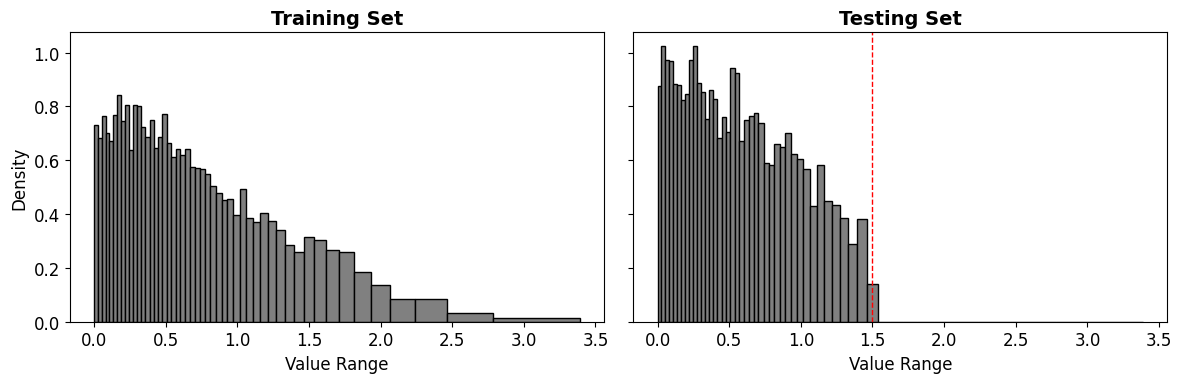

In [25]:
# 1) Constrained random split from right_skewed_data
rng = np.random.default_rng(42)
x = right_skewed_data

threshold = 1.5
test_frac = 0.30

eligible_test_idx = np.where(x <= threshold)[0]
forced_train_idx = np.where(x > threshold)[0]

n_test_target = int(round(test_frac * len(x)))
n_test = min(n_test_target, len(eligible_test_idx))

test_idx = rng.choice(eligible_test_idx, size=n_test, replace=False)
remaining_eligible_idx = np.setdiff1d(eligible_test_idx, test_idx, assume_unique=False)
train_idx = np.concatenate([remaining_eligible_idx, forced_train_idx])

rng.shuffle(train_idx)
rng.shuffle(test_idx)

training_set = x[train_idx]
testing_set = x[test_idx]

assert np.all(testing_set <= threshold)
assert len(training_set) + len(testing_set) == len(x)

# 2) Reuse MTB binning from previous cell (for consistency)
# Requires previous cell to have created:
# - bin_edges_from_ranges
# - bin_widths
bin_edges = bin_edges_from_ranges
# bin_widths = np.diff(bin_edges)  # optional; can reuse existing bin_widths

# 3) Density per bin (area sums to 1 in each panel)
train_counts, _ = np.histogram(training_set, bins=bin_edges)
test_counts, _ = np.histogram(testing_set, bins=bin_edges)

train_density = train_counts / (train_counts.sum() * bin_widths)
test_density = test_counts / (test_counts.sum() * bin_widths)

# 4) Plot bars
plt.rcParams.update({"font.size": 12})
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, sharex=True)

axes[0].bar(
    bin_edges[:-1], train_density, width=bin_widths, align="edge",
    edgecolor="black", color="gray"
)
axes[0].set_title("Training Set", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Value Range")
axes[0].set_ylabel("Density")

axes[1].bar(
    bin_edges[:-1], test_density, width=bin_widths, align="edge",
    edgecolor="black", color="gray"
)
axes[1].set_title("Testing Set", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Value Range")
axes[1].axvline(threshold, color="red", linestyle="--", linewidth=1)

plt.tight_layout()
plt.savefig(figs_folder + "bad_split_mtb_density_bar_consistent_bins.svg", format="svg", bbox_inches="tight")
plt.show()

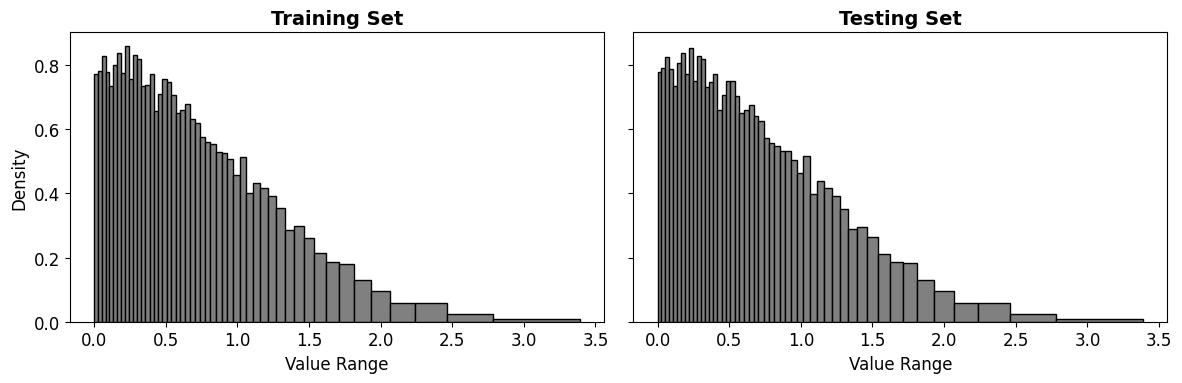

In [26]:
# 1) Stratified split from right_skewed_data (no threshold constraint)
rng = np.random.default_rng(42)
x = right_skewed_data
test_frac = 0.30

# Reuse MTB binning from previous cell for consistency
bin_edges = bin_edges_from_ranges
bin_widths = np.diff(bin_edges)

# Bin labels for all values (0 .. n_bins-1)
all_bins = np.digitize(x, bin_edges[1:-1], right=False)

n_test = int(round(test_frac * len(x)))
n_bins = len(bin_edges) - 1

# Per-bin pools (absolute indices in x)
pool_by_bin = [np.where(all_bins == b)[0] for b in range(n_bins)]
counts_by_bin = np.array([len(p) for p in pool_by_bin], dtype=int)

if counts_by_bin.sum() == 0:
    raise ValueError("No samples found for stratified split.")

# Allocate test counts per bin proportionally
raw_alloc = counts_by_bin / counts_by_bin.sum() * n_test
alloc = np.floor(raw_alloc).astype(int)
alloc = np.minimum(alloc, counts_by_bin)

remaining = n_test - alloc.sum()
if remaining > 0:
    frac = raw_alloc - np.floor(raw_alloc)
    for b in np.argsort(-frac):
        if remaining == 0:
            break
        if alloc[b] < counts_by_bin[b]:
            alloc[b] += 1
            remaining -= 1

if remaining > 0:
    for b in np.argsort(-(counts_by_bin - alloc)):
        if remaining == 0:
            break
        spare = counts_by_bin[b] - alloc[b]
        if spare > 0:
            take = min(spare, remaining)
            alloc[b] += take
            remaining -= take

# Sample test indices stratified by bin
test_idx_parts = []
for b in range(n_bins):
    k = alloc[b]
    if k > 0:
        test_idx_parts.append(rng.choice(pool_by_bin[b], size=k, replace=False))

test_idx = np.concatenate(test_idx_parts) if len(test_idx_parts) > 0 else np.array([], dtype=int)

# Train = complement
mask = np.ones(len(x), dtype=bool)
mask[test_idx] = False
train_idx = np.where(mask)[0]

rng.shuffle(train_idx)
rng.shuffle(test_idx)

training_set = x[train_idx]
testing_set = x[test_idx]

assert len(training_set) + len(testing_set) == len(x)

# 2) Density per bin on same MTB edges
train_counts, _ = np.histogram(training_set, bins=bin_edges)
test_counts, _ = np.histogram(testing_set, bins=bin_edges)

train_density = train_counts / (train_counts.sum() * bin_widths)
test_density = test_counts / (test_counts.sum() * bin_widths)

# 3) Plot
plt.rcParams.update({"font.size": 12})
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, sharex=True)

axes[0].bar(
    bin_edges[:-1], train_density, width=bin_widths, align="edge",
    edgecolor="black", color="gray"
)
axes[0].set_title("Training Set", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Value Range")
axes[0].set_ylabel("Density")

axes[1].bar(
    bin_edges[:-1], test_density, width=bin_widths, align="edge",
    edgecolor="black", color="gray"
)
axes[1].set_title("Testing Set", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Value Range")

plt.tight_layout()
plt.savefig(figs_folder + "bad_split_mtb_density_bar_stratified_no_threshold.svg", format="svg", bbox_inches="tight")
plt.show()